# Kimi Delta Attention: a forget gate per channel

*Kimi Team (Moonshot AI), "Kimi Linear: An Expressive, Efficient Attention Architecture", 2025 ([arXiv 2510.26692](https://arxiv.org/abs/2510.26692)). Used in Kimi Linear and Kimi K3 (69 KDA layers with 24 gated MLA layers, per the diagram). Notebook 6 of 9 in the "How LLMs build on each other" series. Read notebook 5 first.*

**TL;DR.** Gated DeltaNet forgets with **one number per head**: at each token, every channel of the memory decays by the same factor $\alpha_t$. **Kimi Delta Attention (KDA)** replaces that number by a **vector** $\alpha_t\in(0,1)^{d_k}$, one decay rate per key channel:

$$ S_t = \big(I-\beta_tk_tk_t^\top\big)\,\mathrm{Diag}(\alpha_t)\,S_{t-1} + \beta_t k_t v_t^\top, \qquad o_t = S_t^\top q_t . $$

The Kimi team argues this gives the layer a learned sense of *position* (some channels forget fast, some slowly, so the memory itself encodes how long ago something was written), which is why their global-attention layers can run with no positional encoding at all. Two practical problems come with per-channel decay: the chunkwise algorithm has to fold decays into $q$ and $k$ and divide by them, which is numerically delicate, and the layer must still fit in the same hybrid as before (3 KDA layers to 1 global attention layer).

We build KDA, prove it contains Gated DeltaNet as a special case, implement the chunkwise algorithm, show what a vector of decay rates can express that a single rate cannot, and test the position claim on small trained models.

| step | what we do |
|---|---|
| 1 | the update, and what changes against Gated DeltaNet |
| 2 | what a vector of decay rates can express: a learned positional kernel |
| 3 | the chunkwise algorithm, and where the numerics get delicate |
| 4 | the block: parameterisation, output gate, 3 : 1 hybrid with NoPE attention |
| 5 | experiment: lag recall and associative recall, scalar gate vs channel gate |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. The update

Notebook 5 ended with the gated delta rule $S_t=\alpha_t\,S_{t-1}(I-\beta_tk_tk_t^\top)+\beta_tv_tk_t^\top$ with $S\in\mathbb{R}^{d_v\times d_k}$ and a scalar $\alpha_t$. The Kimi paper writes the state transposed ($S\in\mathbb{R}^{d_k\times d_v}$) and applies the decay to the rows, one for each key channel:

$$ S_t = \big(I-\beta_tk_tk_t^\top\big)\,\mathrm{Diag}(\alpha_t)\,S_{t-1} + \beta_t k_tv_t^\top \qquad (\text{paper eq. 1}) . $$

Reading it left to right: first **decay** channel $c$ of the memory by $\alpha_{t,c}$, then **erase** along the new key $k_t$ (the delta rule's correction), then **write** $\beta_tk_tv_t^\top$. If all entries of $\alpha_t$ are equal, $\mathrm{Diag}(\alpha_t)=\alpha_t I$ and we are back to Gated DeltaNet (up to the transposed layout). Both facts we check on random numbers, using the kit's `kda_recurrent`:

In [2]:
def linear_attn_recurrent(q, k, v, alpha=None, beta=None, rule="delta"):
    """One head, recurrent form.  q,k [T,dk]  v [T,dv]  alpha,beta [T]  ->  o [T,dv], S [dv,dk].
    rule = "linear"  : S_t = S_{t-1} + v k^T                                  (plain linear attention)
    rule = "decay"   : S_t = a S_{t-1} + v k^T                                (Mamba-2 style forget gate)
    rule = "delta"   : S_t = S_{t-1}(I - b k k^T) + b v k^T                   (DeltaNet)
    rule = "gdelta"  : S_t = S_{t-1} a (I - b k k^T) + b v k^T                (Gated DeltaNet, paper eq. 10)"""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dv, dk, dtype=q.dtype)
    o = []
    for t in range(T):
        kt, vt = k[t], v[t]
        a = alpha[t] if alpha is not None else 1.0
        b = beta[t] if beta is not None else 1.0
        if rule == "linear":
            S = S + torch.outer(vt, kt)
        elif rule == "decay":
            S = a * S + torch.outer(vt, kt)
        elif rule == "delta":
            S = S - b * torch.outer(S @ kt, kt) + b * torch.outer(vt, kt)
        elif rule == "gdelta":
            S = a * (S - b * torch.outer(S @ kt, kt)) + b * torch.outer(vt, kt)
        o.append(S @ q[t])
    return torch.stack(o), S


def gated_delta_chunkwise(q, k, v, alpha, beta, C=8):
    """Gated DeltaNet, chunkwise form (paper sec. 3.3): chunks are processed with matmuls and one small
    triangular solve instead of C sequential rank-1 updates.  Returns o [T,dv], final S [dv,dk]."""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dv, dk, dtype=q.dtype)
    outs = []
    for s0 in range(0, T, C):
        Q, Kc, V = q[s0:s0 + C], k[s0:s0 + C], v[s0:s0 + C]
        a, b = alpha[s0:s0 + C], beta[s0:s0 + C]
        n = Q.shape[0]
        g = torch.cumprod(a, 0)                                     # gamma_r: decay from chunk start to r
        Gam = g[:, None] / g[None, :]                               # Gamma_ij = gamma_i / gamma_j
        low = torch.tril(torch.ones(n, n, dtype=q.dtype))
        A = torch.tril(b[:, None] * (Gam * (Kc @ Kc.T)), -1)        # strictLower(diag(b) (Gamma o K K^T))
        Tm = torch.linalg.solve(torch.eye(n, dtype=q.dtype) + A, torch.diag(b))    # (I + A)^-1 diag(b)
        U = Tm @ V                                                  # "pseudo values" (decay already inside)
        Wm = Tm @ (g[:, None] * Kc)                                 # decayed "pseudo keys"
        Ucorr = U - Wm @ S.T                                        # what each token writes after removing what S already predicts
        o = (g[:, None] * Q) @ S.T + (Gam * (Q @ Kc.T) * low) @ Ucorr
        outs.append(o)
        S = g[-1] * S + Ucorr.T @ ((g[-1] / g)[:, None] * Kc)
    return torch.cat(outs), S


def kda_recurrent(q, k, v, alpha, beta):
    """Kimi Delta Attention (Kimi Linear paper eq. 1).  Same as the gated delta rule, but the decay
    alpha_t is a VECTOR over the key channels.  Layout follows the paper: S is [dk, dv].
        S_t = (I - b k k^T) Diag(alpha_t) S_{t-1} + b k v^T ;   o_t = S_t^T q_t"""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dk, dv, dtype=q.dtype)
    o = []
    for t in range(T):
        kt, vt, at, bt = k[t], v[t], alpha[t], beta[t]
        S = at[:, None] * S
        S = S - bt * torch.outer(kt, kt @ S) + bt * torch.outer(kt, vt)
        o.append(S.T @ q[t])
    return torch.stack(o), S


def kda_chunkwise(q, k, v, alpha, beta, C=8):
    """KDA, chunkwise (Kimi Linear sec. 3.1).  alpha [T,dk] per-channel decay.
    The trick that lets per-channel decay stay a matmul: fold the cumulative decay into q and k."""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dk, dv, dtype=q.dtype)
    outs = []
    for s0 in range(0, T, C):
        Q, Kc, V = q[s0:s0 + C], k[s0:s0 + C], v[s0:s0 + C]
        a, b = alpha[s0:s0 + C], beta[s0:s0 + C]
        n = Q.shape[0]
        g = torch.cumprod(a, 0)                                     # [n,dk]: per-channel decay from chunk start
        Kd = g * Kc                                                 # k decayed forward to the chunk start frame
        Ki = Kc / g                                                 # k "undecayed" (used so ratios g_i/g_j appear)
        low = torch.tril(torch.ones(n, n, dtype=q.dtype))
        A = torch.tril(b[:, None] * (Kd @ Ki.T), -1)
        Tm = torch.linalg.solve(torch.eye(n, dtype=q.dtype) + A, torch.diag(b))
        W, U = Tm @ Kd, Tm @ V
        Ucorr = U - W @ S
        o = (g * Q) @ S + ((g * Q) @ Ki.T * low) @ Ucorr
        outs.append(o)
        S = g[-1][:, None] * S + (g[-1] / g * Kc).T @ Ucorr
    return torch.cat(outs), S

In [3]:
dt = torch.float64
T_, dk_, dv_ = 30, 6, 5
q = torch.randn(T_, dk_, dtype=dt); k = F.normalize(torch.randn(T_, dk_, dtype=dt), dim=-1); v = torch.randn(T_, dv_, dtype=dt)
a_scalar, beta = 0.5 + 0.5 * torch.rand(T_, dtype=dt), torch.rand(T_, dtype=dt)
o_kda, S_kda = A.kda_recurrent(q, k, v, a_scalar[:, None].expand(T_, dk_).contiguous(), beta)
o_gdn, S_gdn = A.linear_attn_recurrent(q, k, v, a_scalar, beta, "gdelta")
check("KDA with the same decay in every channel is exactly Gated DeltaNet", torch.allclose(o_kda, o_gdn, atol=1e-12))
check("their states are transposes of each other (paper layout [d_k, d_v] vs [d_v, d_k])", torch.allclose(S_kda, S_gdn.T, atol=1e-12))

a_vec = 0.2 + 0.8 * torch.rand(T_, dk_, dtype=dt)
o_vec, _ = A.kda_recurrent(q, k, v, a_vec, beta)
print("with a vector of decays the output is different from any scalar-gate model: max |diff| to GDN with the mean decay =",
      round((o_vec - A.linear_attn_recurrent(q, k, v, a_vec.mean(-1), beta, "gdelta")[0]).abs().max().item(), 3))

PASS - KDA with the same decay in every channel is exactly Gated DeltaNet 
PASS - their states are transposes of each other (paper layout [d_k, d_v] vs [d_v, d_k]) 
with a vector of decays the output is different from any scalar-gate model: max |diff| to GDN with the mean decay = 0.816


## 2. What a vector of decay rates can express

Strip the layer down to see what the decay does by itself. Suppose there were no erase step ($\beta$ small enough to ignore it, i.e. the write only) and the decay rates were fixed constants $\alpha_c$. Unrolling the recurrence, token $i$'s contribution to the output at time $t$ is

$$ o_t = \sum_{i\le t} \Big(\sum_{c} q_{t,c}\, k_{i,c}\, \alpha_c^{\,t-i}\Big)\, v_i . $$

The inner sum is a **weight that depends on the distance** $\Delta=t-i$. With a scalar gate ($\alpha_c=\alpha$ for all $c$) the distance dependence is a single exponential $\alpha^\Delta$ multiplying the content weight $q\cdot k$: *recency, and nothing more*. With a per-channel gate the dependence is a **sum of exponentials with different rates**, weighted by how much each channel contributes. Sums of exponentials with mixed signs can make shapes a single exponential cannot, including a peak at one particular distance.

This is the same reason RoPE works. The paper's Section 6.1 makes the comparison: RoPE rotates each channel pair by an angle proportional to distance (a position-dependent factor per channel), and linear attention with a data-dependent decay applies a (diagonal, here) position-dependent factor per channel: both are "multiplicative position encodings", and the decay one is learned and data-dependent.

We make this concrete without training anything. Target: a kernel that picks out exactly one distance, $\Delta=4$ ("what came four tokens ago?"). Fit it by least squares with (a) one decay rate and a free amplitude, (b) 16 channels with decay rates spread from fast to slow, free amplitudes:

one decay rate (best alpha = 0.91): residual 0.957
16 channels, rates 0.10..0.98:     residual 0.109


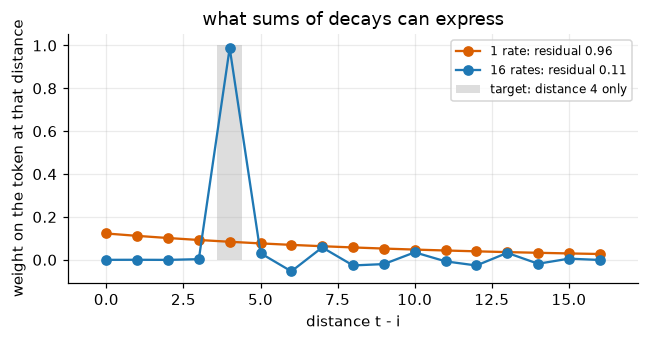

PASS - 16 channels with different rates fit a one-distance kernel far better than a single rate 0.11 vs 0.96


In [4]:
Delta = np.arange(0, 17)
target = (Delta == 4).astype(float)

def fit(rates):
    B = np.stack([r ** Delta for r in rates], 1)                      # basis: alpha_c^Delta, one column per channel
    coef, *_ = np.linalg.lstsq(B, target, rcond=None)
    return B @ coef, np.linalg.norm(B @ coef - target)

best_scalar = min(((fit([a]), a) for a in np.linspace(0.05, 0.99, 95)), key=lambda z: z[0][1])
(fit_s, res_s), a_best = best_scalar
rates16 = 1 - np.geomspace(0.9, 0.02, 16)                              # 16 channels, from fast (0.1) to slow (0.98) decay
fit_v, res_v = fit(rates16)
print(f"one decay rate (best alpha = {a_best:.2f}): residual {res_s:.3f}")
print(f"16 channels, rates {rates16.min():.2f}..{rates16.max():.2f}:     residual {res_v:.3f}")

fig, ax = plt.subplots(figsize=(6.0, 3.2))
ax.bar(Delta, target, color="#dddddd", label="target: distance 4 only")
ax.plot(Delta, fit_s, marker="o", color=C["orange"], label=f"1 rate: residual {res_s:.2f}")
ax.plot(Delta, fit_v, marker="o", color=C["blue"], label=f"16 rates: residual {res_v:.2f}")
ax.set_xlabel("distance t - i"); ax.set_ylabel("weight on the token at that distance"); ax.legend(fontsize=8)
ax.set_title("what sums of decays can express"); plt.tight_layout(); plt.show()
check("16 channels with different rates fit a one-distance kernel far better than a single rate", res_v < 0.4 * res_s, f"{res_v:.2f} vs {res_s:.2f}")

One rate gives a nearly flat, steadily decaying line (it can only say "recent is a little more important"), so it cannot isolate a distance. Sixteen rates reproduce the spike at distance 4, with small wiggles elsewhere, by combining exponentials with weights of both signs. This is an analytic fit with a free choice of amplitudes, not a trained layer; section 5 asks whether a *trained* layer finds it. In a real KDA layer the rates $\alpha_t$ also depend on the token (they are computed from $x_t$), so the kernel is not fixed but is chosen by the data.

## 3. The chunkwise algorithm, and where its numerics get delicate

As in notebook 5 we want matrix multiplications instead of a loop over time. For a scalar decay the chunk's cumulative decay $\gamma_r=\prod_{i\le r}\alpha_i$ is one number per position, and $\Gamma_{ij}=\gamma_i/\gamma_j$ is a matrix that multiplies the score matrix elementwise. With a **vector** decay, $\gamma_r$ is a vector (one per channel), and the decay between $i$ and $j$ depends on the channel, so it cannot be applied after the dot product $q\cdot k$: it must be applied **inside** it. The trick is to fold the cumulative decay into the vectors before the product, $\tilde q_t=\gamma_t\odot q_t$ and $\tilde k_i = k_i/\gamma_i$, so that

$$ \sum_c q_{t,c}\,\Big(\tfrac{\gamma_{t,c}}{\gamma_{i,c}}\Big)\,k_{i,c} = \tilde q_t\cdot\tilde k_i , $$

an ordinary matrix product. The rest follows the delta-rule algorithm of notebook 5 (the triangular solve and pseudo-values, the paper's eq. 3 to 9). The kit's `kda_chunkwise` (shown in full in the first code cell above) does this in the two lines `Kd = g * Kc` and `Ki = Kc / g`. The check, as before, is against the recurrence:

In [5]:
T_, dk_, dv_ = 64, 8, 6
q = torch.randn(T_, dk_, dtype=dt); k = F.normalize(torch.randn(T_, dk_, dtype=dt), dim=-1); v = torch.randn(T_, dv_, dtype=dt)
alpha = 0.6 + 0.4 * torch.rand(T_, dk_, dtype=dt); beta = torch.rand(T_, dtype=dt)
o_rec, S_rec = A.kda_recurrent(q, k, v, alpha, beta)
for C_ in [1, 4, 16, 64]:
    o_chk, S_chk = A.kda_chunkwise(q, k, v, alpha, beta, C=C_)
    print(f"chunk {C_:3d}: max |output difference| {(o_rec - o_chk).abs().max().item():.1e}")
    check(f"KDA chunkwise (C={C_}) equals the recurrence", torch.allclose(o_rec, o_chk, atol=1e-9))

chunk   1: max |output difference| 1.8e-15
PASS - KDA chunkwise (C=1) equals the recurrence 
chunk   4: max |output difference| 1.0e-15
PASS - KDA chunkwise (C=4) equals the recurrence 
chunk  16: max |output difference| 1.0e-15
PASS - KDA chunkwise (C=16) equals the recurrence 
chunk  64: max |output difference| 8.9e-16
PASS - KDA chunkwise (C=64) equals the recurrence 


**The numerical catch.** $\tilde k_i=k_i/\gamma_i$ divides by a cumulative product that shrinks exponentially with position in the chunk. With a decay of 0.3 per step, after 32 steps $\gamma\approx 2\times10^{-17}$ and $1/\gamma\approx 5\times10^{16}$. Single precision can hold such numbers, half precision (the format tensor cores want; largest value 65,504, smallest positive about $6\times10^{-8}$) cannot: a product of 16 decays of 0.3 is already $4\times10^{-9}$ and rounds to zero. The paper discusses exactly this: earlier fine-grained-decay layers (GLA, and layers built on the DPLR form) do these steps in the logarithmic domain with a second level of chunking in full precision, which blocks the fast half-precision matmuls; KDA instead ties both vectors of its rank-one transition to the same key $k_t$, which removes several of the extra matmuls and, they report, makes the kernel about twice as fast as a general DPLR one (their Figure 2).

We can see the problem on a CPU by running our chunkwise algorithm in single precision and comparing against the double-precision recurrence, for chunk sizes from 8 to 64, with moderate and strong decay:

In [6]:
def f32_error(lo, hi, C_, T_=128, seed=0):
    g = torch.Generator().manual_seed(seed)
    d64 = torch.float64
    q = torch.randn(T_, 8, generator=g, dtype=d64); k = F.normalize(torch.randn(T_, 8, generator=g, dtype=d64), dim=-1)
    v = torch.randn(T_, 6, generator=g, dtype=d64)
    al = lo + (hi - lo) * torch.rand(T_, 8, generator=g, dtype=d64); be = torch.rand(T_, generator=g, dtype=d64)
    ref, _ = A.kda_recurrent(q, k, v, al, be)
    try:
        out, _ = A.kda_chunkwise(q.float(), k.float(), v.float(), al.float(), be.float(), C=C_)
    except torch.linalg.LinAlgError:                                  # the cumulative decay underflowed: the solve sees a singular matrix
        return float("inf")
    return (out.double() - ref).abs().max().item() if torch.isfinite(out).all() else float("inf")

print(f"{'decay range':>14s} " + " ".join(f"{'C=' + str(c):>10s}" for c in [8, 16, 32, 64]))
errs = {}
for lo, hi in [(0.8, 1.0), (0.4, 0.8), (0.05, 0.3)]:
    row = [f32_error(lo, hi, c) for c in [8, 16, 32, 64]]
    errs[(lo, hi)] = row
    print(f"{lo:5.2f}..{hi:4.2f}    " + " ".join(f"{e:10.1e}" for e in row))
check("with mild decay the single-precision chunkwise result is accurate at every chunk size (below 1e-3)", max(errs[(0.8, 1.0)]) < 1e-3)

   decay range        C=8       C=16       C=32       C=64
 0.80..1.00       1.0e-06    5.6e-07    6.3e-07    6.5e-07
 0.40..0.80       5.2e-07    5.3e-07    5.3e-07    5.4e-07
 0.05..0.30       3.0e-07    3.6e-07    5.2e-07        inf
PASS - with mild decay the single-precision chunkwise result is accurate at every chunk size (below 1e-3) 


**Result (largest error of the single-precision chunkwise output against the double-precision recurrence).** For mild and moderate decay (ranges 0.8 to 1.0 and 0.4 to 0.8) the error is about $5\times10^{-7}$ to $10^{-6}$ at every chunk size, which is ordinary single-precision rounding, so in float32 the folded decay is harmless there. With strong decay (0.05 to 0.3) the error is still about $3$ to $5\times10^{-7}$ up to $C=32$, and at $C=64$ the computation **fails outright** (`inf` in the table): the cumulative decay of 64 steps at about 0.17 is roughly $10^{-49}$, below the smallest positive single-precision number ($10^{-38}$ for normal numbers), so $\gamma$ becomes zero, the division produces infinities and the triangular solve reports a singular matrix. So the hazard here is not a gradual loss of digits but a **hard range limit** that depends on the decay strength and the chunk length. Half precision has a far smaller range and reaches the same wall at much shorter chunks, which is why the paper's kernels need tricks (secondary chunking, working in the log domain, or the cheaper structure KDA uses) when the decay is fine-grained.

## 4. The block

The paper's neural parameterisation (their Section 4), for one head with $d_k=d_v=128$:

$$ q_t,k_t=\mathrm{L2Norm}(\mathrm{Swish}(\mathrm{ShortConv}(W_{q/k}x_t))),\quad v_t=\mathrm{Swish}(\mathrm{ShortConv}(W_vx_t)), $$
$$ \alpha_t=f(W^\uparrow_\alpha W^\downarrow_\alpha x_t)\in[0,1]^{d_k},\qquad \beta_t=\mathrm{Sigmoid}(W_\beta x_t)\in[0,1] . $$

The decay vector comes from a **low-rank** projection (rank equal to the head dimension), so a full $d\times d_k$ matrix is not needed per head. And before the output projection the result goes through a head-wise RMSNorm and a **sigmoid output gate**, also low-rank:

$$ o_t = W_o\Big(\mathrm{Sigmoid}(W^\uparrow_g W^\downarrow_g x_t)\odot \mathrm{RMSNorm}\big(\mathrm{KDA}(q_t,k_t,v_t,\alpha_t,\beta_t)\big)\Big) . $$

That output gate is the attention output gate of notebook 2, applied to the linear layer; the paper notes it also helps with the attention sink. The block as drawn in the paper:

![The paper's Figure 3: the Kimi Linear architecture. A stack of blocks, each a token-mixing layer followed by a mixture-of-experts layer. N KDA layers are interleaved with one MLA layer, with N = 3. The expanded KDA layer shows the projections, short convolutions, L2 normalisation and the sigmoid gates.](../../assets/architecture_gallery/kda_fig3_architecture.png)

**Hybrid and NoPE.** The memory of a linear layer is fixed in size, so exact retrieval from far back is weak; one full-attention layer in every four (MLA, from the DeepSeek notebooks) provides it. The paper found a uniform **3 : 1** ratio of KDA to MLA layers gave the best quality-to-throughput trade-off, and alternates whole layers instead of mixing heads inside a layer, for simplicity of infrastructure. The distinctive choice is **NoPE** for the MLA layers: no positional encoding at all. All position information is the job of the KDA layers. Why can this work? A softmax attention layer *without* positional encoding is blind to the order of the tokens it reads: reordering the earlier tokens leaves the output of the latest token unchanged, while a recurrence is sensitive to order. The two facts, checked:

In [7]:
torch.manual_seed(0)
d, H_ = 32, 4
nope = A.Attn(d, H_, rope=False)
x = torch.randn(1, 20, d)
perm = torch.randperm(19)
x_perm = torch.cat([x[:, :19][:, perm], x[:, 19:]], 1)                # shuffle the 19 earlier tokens, keep the last
d_att = (nope(x)[:, -1] - nope(x_perm)[:, -1]).abs().max().item()
print(f"NoPE softmax attention: change at the last position when earlier tokens are shuffled = {d_att:.2e}")
check("attention without positional encoding cannot see the order of earlier tokens", d_att < 1e-5)

dt = torch.float64
q = torch.randn(20, 6, dtype=dt); k = F.normalize(torch.randn(20, 6, dtype=dt), dim=-1); v = torch.randn(20, 5, dtype=dt)
beta = torch.full((20,), 0.5, dtype=dt)
alpha = (0.3 + 0.65 * torch.rand(6, dtype=dt)).expand(20, 6).contiguous()        # fixed per-channel rates
o1, _ = A.kda_recurrent(q, k, v, alpha, beta)
q2, k2, v2 = [torch.cat([a_[:19][perm], a_[19:]]) for a_ in (q, k, v)]
o2, _ = A.kda_recurrent(q2, k2, v2, alpha, beta)
d_kda = (o1[-1] - o2[-1]).abs().max().item()
print(f"KDA: change at the last position when earlier tokens are shuffled = {d_kda:.2e}")
check("KDA output depends on the order of earlier tokens", d_kda > 1e-3)

NoPE softmax attention: change at the last position when earlier tokens are shuffled = 3.73e-08
PASS - attention without positional encoding cannot see the order of earlier tokens 
KDA: change at the last position when earlier tokens are shuffled = 5.97e-01
PASS - KDA output depends on the order of earlier tokens 


So a stack in which the global layers are NoPE and the KDA layers carry order is self-consistent: the global layers do content-based lookup over the whole cache, and the recurrent layers supply the *when*. We cannot test the paper's quality claims for this, but we can test its core mechanism at small scale.

## 5. Experiment: does a channel gate learn position?

Two small trained tasks, with one linear layer each (as in notebook 5; $d_k=d_v=16$, short convolution on the input, gates computed from the token), comparing three layers:

- **GDN**: scalar decay, one gate value per token (initial bias 3, so $\alpha\approx0.95$).
- **KDA, flat init**: vector decay, all channels start at the same $\alpha\approx0.95$.
- **KDA, spread init**: vector decay, channels start at *different* rates, $\alpha$ from 0.5 to 0.99. This is **our choice** (the paper does not describe its initialisation); including both KDA variants separates "a vector gate" from "a vector gate that starts out multi-scale".

**Task A: lag recall.** The input is a random token sequence (16 symbols); at every position $t\ge 4$ the layer must output the token seen exactly **4 steps earlier**. There are no content cues, only position: a model that cannot represent "how long ago" cannot solve it.

**Task B: associative recall**, with 16 key-value pairs, as in notebook 5.

In [8]:
DKV, DM = 16, 48
LAG = 4

def lag_batch(B, T, g, V=16):
    x = torch.randint(0, V, (B, T), generator=g)
    return x, x[:, :-LAG]                                       # target at position t >= LAG is x[t - LAG]

KV, VV = 32, 32
def mqar_batch(B, N, g):
    keys = torch.stack([torch.randperm(KV, generator=g)[:N] for _ in range(B)])
    vals = torch.randint(0, VV, (B, N), generator=g) + KV
    pairs = torch.stack([keys, vals], -1).reshape(B, 2 * N)
    perm = torch.stack([torch.randperm(N, generator=g) for _ in range(B)])
    return torch.cat([pairs, keys.gather(1, perm)], 1), vals.gather(1, perm) - KV

class LinNet(nn.Module):
    """kind: "gdn" (scalar decay) | "kda_flat" | "kda_spread".  State layout [B, d_k, d_v] as in the Kimi paper."""
    def __init__(self, kind, vocab, out):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(vocab, DM)
        self.q, self.k, self.v = (nn.Linear(2 * DM, DKV, bias=False) for _ in range(3))
        na = 1 if kind == "gdn" else DKV
        self.a, self.b = nn.Linear(2 * DM, na), nn.Linear(2 * DM, 1)
        with torch.no_grad():
            self.a.weight.mul_(0.1)
            if kind == "kda_spread":
                self.a.bias.copy_(torch.logit(torch.linspace(0.5, 0.99, DKV)))
            else:
                self.a.bias.fill_(3.0)
        self.out = nn.Linear(DKV, out)

    def forward(self, tok):
        B, T = tok.shape
        x = self.emb(tok)
        x = torch.cat([x, F.pad(x, (0, 0, 1, 0))[:, :-1]], -1)
        q, k, v = F.normalize(self.q(x), dim=-1), F.normalize(self.k(x), dim=-1), self.v(x)
        alpha, beta = torch.sigmoid(self.a(x)), torch.sigmoid(self.b(x))                  # [B,T,1 or d_k], [B,T,1]
        S = torch.zeros(B, DKV, DKV)
        o = []
        for t in range(T):
            kt, vt, bt = k[:, t], v[:, t], beta[:, t, :, None]
            S = alpha[:, t, :, None] * S                                                   # decay (scalar or per channel)
            S = S - bt * kt[..., None] * (kt[:, None, :] @ S) + bt * kt[..., None] * vt[:, None, :]
            o.append((S.transpose(1, 2) @ q[:, t, :, None])[..., 0])
        return self.out(torch.stack(o, 1))

def run_lag(kind, seed, steps=1200, B=64, T=40):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    net = LinNet(kind, 16, 16); opt = torch.optim.Adam(net.parameters(), 3e-3)
    for s in range(steps):
        x, y = lag_batch(B, T, g)
        loss = F.cross_entropy(net(x)[:, LAG:].reshape(-1, 16), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
    x, y = lag_batch(500, T, torch.Generator().manual_seed(999))
    with torch.no_grad():
        return (net(x)[:, LAG:].argmax(-1) == y).float().mean().item(), net

def run_mqar(kind, seed, steps=1200, B=64, N=16):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    net = LinNet(kind, KV + VV, VV); opt = torch.optim.Adam(net.parameters(), 3e-3)
    for s in range(steps):
        tok, ans = mqar_batch(B, N, g)
        loss = F.cross_entropy(net(tok)[:, -N:].reshape(-1, VV), ans.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
    tok, ans = mqar_batch(400, N, torch.Generator().manual_seed(999))
    with torch.no_grad():
        return (net(tok)[:, -N:].argmax(-1) == ans).float().mean().item()

kinds = ["gdn", "kda_flat", "kda_spread"]
lag_acc, mq_acc = {}, {}
t0 = time.time()
for kd in kinds:
    lag_acc[kd] = [run_lag(kd, s)[0] for s in [0, 1]]
    mq_acc[kd] = [run_mqar(kd, s) for s in [0, 1]]
    print(f"{kd:11s} lag-{LAG} recall accuracy {np.round(lag_acc[kd], 3)}   MQAR (16 pairs) accuracy {np.round(mq_acc[kd], 3)}   ({time.time() - t0:.0f} s)")
print(f"chance: lag 1/16 = {1 / 16:.3f}, MQAR 1/32 = {1 / 32:.3f}")

gdn         lag-4 recall accuracy [0.423 0.402]   MQAR (16 pairs) accuracy [0.995 0.993]   (164 s)


kda_flat    lag-4 recall accuracy [0.792 0.808]   MQAR (16 pairs) accuracy [0.993 0.994]   (343 s)


kda_spread  lag-4 recall accuracy [0.835 0.788]   MQAR (16 pairs) accuracy [0.917 0.927]   (520 s)
chance: lag 1/16 = 0.062, MQAR 1/32 = 0.031


**Result (2 seeds each; accuracy).**

| layer | lag-4 recall (chance 0.06) | associative recall, 16 pairs (chance 0.03) |
|---|---|---|
| GDN (one decay per head) | 0.42, 0.40 | 0.995, 0.993 |
| KDA, flat init | 0.79, 0.81 | 0.993, 0.994 |
| KDA, spread init | 0.84, 0.79 | 0.917, 0.927 |

**Lag recall is where the vector gate matters**: the scalar gate reaches about 0.41, roughly seven times chance but far from solved, while both KDA variants reach about 0.8. That fits the argument of section 2: with one decay rate per head the layer has only a single "clock" (the magnitude of old content), whereas a vector of rates gives it many, from which the age of a token can be read. The flat-init KDA, whose channels *start* with identical decay, reaches the same accuracy as the spread-init one, so the gain comes from the layer being *able* to learn different rates, not from our initialisation. Neither is perfect at lag 4 (about 0.8), so this is evidence for a capability, not a solved task. **Associative recall shows no benefit**: GDN and flat-init KDA are equally near-perfect, and spread-init KDA is *worse* (0.92). A plausible reason, which we did not test, is that the spread init starts some channels with decay near 0.5 (fast forgetting), which hurts a task that needs long retention. What this does not tell us: whether the lag-recall advantage translates into anything in language (the paper's evidence is its long-context and downstream results at 48B).

## What this notebook did and did not show

**Shown (checks).** KDA with equal decay in all channels is Gated DeltaNet; the chunkwise algorithm with folded decays reproduces the recurrence at every chunk size; a bank of exponentials with different rates can fit a one-distance kernel that a single exponential cannot (an analytic fit, not a trained layer); softmax attention without positional encoding is blind to the order of earlier tokens while KDA is not. Sections 3 and 5 report numerics and trained results with their interpretation under each.

![The paper's Figure 1. (a) Performance against decoding acceleration: on MMLU-Pro (4k context) Kimi Linear scores 51.0 against 47.2 for MLA and 47.9 for GDN-H; on RULER (128k context) it scores 84.3 at 3.98x acceleration. (b) Time per output token against decoding length: Kimi Linear stays low, 6.3x faster than MLA at 1M tokens (1.84 ms against 11.48 ms).](../../assets/architecture_gallery/kda_fig1_results.png)

**Not shown.** The paper's results are on 48B-total / 3B-active models trained on 1.4T tokens (the figure above and the abstract: better quality than full MLA on the evaluated tasks, a KV cache reduced by up to 75%, and up to 6x decoding throughput at a 1M-token context, with identical training recipes); we do not train anything that large, time any GPU kernel, or test long-context retrieval. Our trained layers are single layers on synthetic tasks with 2 seeds. We did not implement the low-rank gate parameterisation, the short convolution on $q$, $k$, $v$ beyond a width-2 mix, the head-wise normalisation, the output gate, or MLA.

**Next.** Notebook 7 goes back to mixture of experts: LatentMoE routes tokens in the full width but computes the experts in a compressed latent space.

In [9]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 10 | failed: 0
